# 03 - Case study: Free University MACS (Computer Science & Mathematics), full population

MACS competitive score = Georgian scaled + foreign language scaled + 10 x Mathematics scaled
(verified exactly on all admitted students, residual 0). Program codes: 03601054 (2025), 03601044 (2026);
the physics route (03601058 / 03601048) is excluded here.

The rating lists contain every test-taker's scaled score per subject, so the MACS score can be computed
for every student who sat Georgian + a foreign language + Mathematics, not only for those admitted.
Raw scores and exam versions are recovered from scaled scores (src/scores.py; exact for 99% of
admitted students in mathematics).

In [1]:
from common import *
from load import load_equating, load_rating, load_admissions, load_choices
from scores import recover_raw, check_recovery

MACS = {2025: "03601054", 2026: "03601044"}
eq = load_equating()
FL = ["ENG", "RUS", "GER", "FRE"]


def population(year):
    r = load_rating(year)
    rec = recover_raw(r, eq)
    wide = r.pivot(index="exam_id", columns="subject", values="scaled").reindex(columns=sorted(set(r.subject) | set(FL)))
    raw = rec.pivot(index="exam_id", columns="subject", values="raw")
    ver = rec.pivot(index="exam_id", columns="subject", values="version")
    fl = wide[FL].bfill(axis=1).iloc[:, 0]
    fl_name = wide[FL].notna().idxmax(axis=1).where(wide[FL].notna().any(axis=1))
    p = pd.DataFrame({"geo_sc": wide.get("GEO"), "fl_sc": fl, "fl": fl_name, "math_sc": wide.get("MATH"),
                      "geo_raw": raw.get("GEO"), "eng_raw": raw.get("ENG"), "math_raw": raw.get("MATH"),
                      "math_version": ver.get("MATH")})
    p = p.dropna(subset=["geo_sc", "fl_sc", "math_sc"])
    p["comp"] = (p.geo_sc + p.fl_sc + 10 * p.math_sc).round(1)
    p.insert(0, "year", year)
    return p, rec


pops, recs, adms = {}, {}, {}
for y in MACS:
    pops[y], recs[y] = population(y)
    adms[y] = load_admissions(y)
    print(y, "students with Georgian + foreign language + math:", len(pops[y]))
    print(check_recovery(recs[y], adms[y]).round(4).to_string(index=False))

2025 students with Georgian + foreign language + math: 12890
subject  n_admitted  raw_exact  raw_within1  cells_multi_scaled  cells
    ENG       28962     0.8511       0.9376                 191    272
    GEO       30068     0.8460       0.8661                 170    244
   HIST       14418     0.9311       0.9314                  62    165
   MATH        9865     0.9172       1.0000                  28    100


2026 students with Georgian + foreign language + math: 13401
subject  n_admitted  raw_exact  raw_within1  cells_multi_scaled  cells
    ENG       30002     0.8641       0.9482                 191    269
    GEO       31105     0.9142       0.9430                 166    243
   HIST       14366     0.9429       0.9768                  62    170
   MATH       11388     0.9924       0.9924                   0    103


## 1. Cutoff and the crowd around it

In [2]:
rows = []
for y, code in MACS.items():
    a, p = adms[y], pops[y]
    macs = a[a.prog_code == code]
    cut = macs.comp.min()
    pt = 10 * 1.3  # one raw math point at the top ~ 1.3 scaled x weight 10
    rows.append({
        "year": y, "seats_math_route": len(macs), "cutoff": cut, "top_admitted": macs.comp.max(),
        "admitted_range": macs.comp.max() - cut,
        "admitted_math_raw_min": macs.el1_raw.min(), "admitted_math_raw_max": macs.el1_raw.max(),
        "n_at_or_above_cutoff": (p.comp >= cut).sum(),
        "n_within_1pt_below": ((p.comp < cut) & (p.comp >= cut - pt)).sum(),
        "n_within_2pt_below": ((p.comp < cut) & (p.comp >= cut - 2 * pt)).sum(),
        "admitted_ids_in_population": macs.exam_id.isin(p.index).mean(),
        "comp_rebuild_max_resid": (macs.set_index("exam_id").comp - p.comp.reindex(macs.exam_id)).abs().max(),
    })
cut_t = pd.DataFrame(rows)
cut_t.to_csv(OUT / "t03_macs_cutoff_crowd.csv", index=False)
cut_t.T

,0,1
year,2025.0,2026.0
seats_math_route,57.0,57.0
cutoff,2274.1,2215.4
top_admitted,2308.8,2243.8
admitted_range,34.7,28.4
admitted_math_raw_min,49.0,48.0
admitted_math_raw_max,51.0,51.0
n_at_or_above_cutoff,129.0,180.0
n_within_1pt_below,42.0,93.0
n_within_2pt_below,107.0,181.0


## 2. How many students share each top math score, nationally vs. MACS seats

In [3]:
rows = []
for y in MACS:
    p = pops[y]
    a = adms[y]
    macs = a[a.prog_code == MACS[y]]
    nat = eq[(eq.year == y) & (eq.subject == "MATH")].groupby("raw").n.sum()
    for raw in range(45, 52):
        rows.append({"year": y, "math_raw": raw, "national_test_takers": nat.get(raw, 0),
                     "with_geo_and_fl": int((p.math_raw == raw).sum()),
                     "admitted_to_macs": int((macs.el1_raw == raw).sum())})
share = pd.DataFrame(rows)
share.to_csv(OUT / "t03_math_top_scores_vs_macs.csv", index=False)
share.pivot(index="math_raw", columns="year")

national_test_takers      with_geo_and_fl      admitted_to_macs     
year                     2025 2026            2025 2026             2025 2026
math_raw                                                                     
45                         64  110              63  109                0    0
46                         60  103              59  101                0    0
47                         69  111              67  108                0    0
48                         65   82              65   81                0    1
49                         59   80              59   80               14    9
50                         53   89              51   86               19   23
51                         47   67              46   65               24   24

## 3. Ties and score resolution among the top of the MACS ranking

In [4]:
rows = []
for y in MACS:
    p = pops[y].sort_values("comp", ascending=False)
    cut = cut_t.set_index("year").loc[y, "cutoff"]
    top = p[p.comp >= cut]
    vc = top.comp.value_counts()
    rows.append({"year": y, "n_above_cutoff": len(top), "distinct_scores": len(vc),
                 "students_sharing_a_score": int(vc[vc > 1].sum()), "largest_tie": int(vc.max()),
                 "math_raw_distinct": top.math_raw.nunique(),
                 "pct_math_raw_ge_49": 100 * (top.math_raw >= 49).mean(),
                 "pct_eng_at_max_70": 100 * (top.eng_raw == 70).mean(),
                 "pct_eng_ge_68": 100 * (top.eng_raw >= 68).mean(),
                 "pct_geo_ge_55": 100 * (top.geo_raw >= 55).mean()})
    m = adms[y][adms[y].prog_code == MACS[y]]
    vc = m.comp.value_counts()
    rows.append({"year": y, "group": "admitted", "n_above_cutoff": len(m), "distinct_scores": len(vc),
                 "students_sharing_a_score": int(vc[vc > 1].sum()), "largest_tie": int(vc.max()),
                 "math_raw_distinct": m.el1_raw.nunique(), "pct_math_raw_ge_49": 100 * (m.el1_raw >= 49).mean(),
                 "pct_eng_at_max_70": 100 * (m.fl_raw == 70).mean(), "pct_eng_ge_68": 100 * (m.fl_raw >= 68).mean(),
                 "pct_geo_ge_55": 100 * (m.geo_raw >= 55).mean()})
ties = pd.DataFrame(rows)
ties["group"] = ties["group"].fillna("all at/above cutoff")
ties.to_csv(OUT / "t03_ties_and_ceilings.csv", index=False)
ties.T

,0,1,2,3
year,2025,2025,2026,2026
n_above_cutoff,129,57,180,57
distinct_scores,102,53,134,52
students_sharing_a_score,51,8,83,10
largest_tie,3,2,3,2
math_raw_distinct,3,3,4,4
pct_math_raw_ge_49,100.0,100.0,96.666667,98.245614
pct_eng_at_max_70,26.356589,31.578947,38.333333,47.368421
pct_eng_ge_68,70.542636,73.684211,77.777778,82.45614
pct_geo_ge_55,60.465116,56.140351,56.666667,45.614035


## 4. What decides the order among admitted MACS students?
Variance decomposition of the competitive score among admitted (math-route) students:
share of Var(comp) attributable to each component (component variance + its covariances, split evenly).

In [5]:
rows = []
for y, code in MACS.items():
    m = adms[y][adms[y].prog_code == code]
    parts = pd.DataFrame({"Georgian": m.geo_sc, "Foreign language": m.fl_sc, "Math x10": 10 * m.el1_sc})
    C = parts.cov()
    tot = C.values.sum()
    for c in parts.columns:
        rows.append({"year": y, "component": c, "sd": parts[c].std(), "share_of_variance": C.loc[c].sum() / tot,
                     "range": parts[c].max() - parts[c].min()})
dec = pd.DataFrame(rows)
dec.to_csv(OUT / "t03_variance_decomposition.csv", index=False)
dec.round(3)

,year,component,sd,share_of_variance,range
0,2025,Georgian,4.660,0.092,17.7
1,2025,Foreign language,0.764,0.029,3.3
2,2025,Math x10,11.140,0.878,30.0
3,2026,Georgian,5.912,0.381,23.0
4,2026,Foreign language,1.480,0.045,6.2
5,2026,Math x10,7.399,0.574,26.0


## 4b. How much is one raw point worth in the MACS competitive score?
Median scaled score at each raw score among all admitted students (2026, English only for the foreign language),
slope over the top range, times the MACS weight. Plus each subject's raw range among the 2026 MACS admits.

In [6]:
a26 = adms[2026]
def per_raw(raw, sc, lo, hi):
    d = pd.DataFrame({"r": raw, "s": sc}).dropna()
    d = d[(d.r >= lo) & (d.r <= hi)].groupby("r").s.median()
    return (d.iloc[-1] - d.iloc[0]) / (d.index[-1] - d.index[0])
eng26 = a26[a26.fl_code == "ENG"]
mat26 = a26[a26.el1_code == "MATH"]
m26 = a26[a26.prog_code == MACS[2026]]
ppr = pd.DataFrame([
    {"subject": "Mathematics", "top_range": "45-51", "weight": 10, "scaled_per_raw": per_raw(mat26.el1_raw, mat26.el1_sc, 45, 51),
     "macs_raw_min": m26.el1_raw.min(), "macs_raw_max": m26.el1_raw.max()},
    {"subject": "English", "top_range": "60-70", "weight": 1, "scaled_per_raw": per_raw(eng26.fl_raw, eng26.fl_sc, 60, 70),
     "macs_raw_min": m26.fl_raw.min(), "macs_raw_max": m26.fl_raw.max()},
    {"subject": "Georgian", "top_range": "50-60", "weight": 1, "scaled_per_raw": per_raw(a26.geo_raw, a26.geo_sc, 50, 60),
     "macs_raw_min": m26.geo_raw.min(), "macs_raw_max": m26.geo_raw.max()},
])
ppr["comp_per_raw"] = ppr.weight * ppr.scaled_per_raw
ppr["raw_pts_to_equal_one_math_pt"] = ppr.comp_per_raw.iloc[0] / ppr.comp_per_raw
ppr.to_csv(OUT / "t03_points_per_raw_2026.csv", index=False)
ppr.round(2)

,subject,top_range,weight,scaled_per_raw,macs_raw_min,macs_raw_max,comp_per_raw,raw_pts_to_equal_one_math_pt
0,Mathematics,45-51,10,1.30,48.0,51.0,13.00,1.00
1,English,60-70,1,0.83,62.0,70.0,0.83,15.66
2,Georgian,50-60,1,1.29,41.0,60.0,1.29,10.08


## 5. Where did the students above the MACS cutoff end up?
Every student at or above the cutoff could have been admitted to MACS if they had ranked it first.
Many chose other programs; the admitted list tells us where each was placed and at which priority.

In [7]:
rows = []
for y, code in MACS.items():
    p, a = pops[y], adms[y]
    cut = cut_t.set_index("year").loc[y, "cutoff"]
    above = p[p.comp >= cut].join(a.set_index("exam_id")[["uni", "prog", "prog_code", "choice"]], how="left")
    above["dest"] = np.where(above.prog_code == code, "Free Uni MACS",
                     np.where(above.prog_code.isna(), "not admitted anywhere (bachelor list)",
                              above.uni.str.replace(r"^(სსიპ|შპს|ა\(ა\)იპ)\s*-?\s*", "", regex=True).str.strip() + " | " + above.prog))
    d = above.dest.value_counts().rename("n").reset_index()
    d.insert(0, "year", y)
    rows.append(d)
    print(y, "choice rank of admitted above-cutoff students:", above.choice.value_counts().sort_index().to_dict())
dest = pd.concat(rows)
dest.to_csv(OUT / "t03_above_cutoff_destinations.csv", index=False)
dest.groupby("year").head(12)

2025 choice rank of admitted above-cutoff students: {1: 128, 2: 1}
2026 choice rank of admitted above-cutoff students: {1: 177, 2: 3}


,year,dest,n
0,2025,Free Uni MACS,57
1,2025,თბილისის თავისუფალი უნივერსიტეტი | ელექტრო და ...,13
2,2025,თბილისის თავისუფალი უნივერსიტეტი | ბიზნესის ად...,13
3,2025,ივანე ჯავახიშვილის სახელობის თბილისის სახელმწი...,11
4,2025,თბილისის თავისუფალი უნივერსიტეტი | ფიზიკა,6
5,2025,თბილისის თავისუფალი უნივერსიტეტი | შენობის სის...,5
6,2025,საქართველოს აგრარული უნივერსიტეტი | ელექტრონულ...,4
7,2025,თბილისის სახელმწიფო სამედიცინო უნივერსიტეტი | ...,3
8,2025,ქუთაისის საერთაშორისო უნივერსიტეტი | კომპიუტერ...,3
9,2025,ივანე ჯავახიშვილის სახელობის თბილისის სახელმწი...,2


## 6. Demand: how many applicants listed MACS (choice counts by priority)

In [8]:
dem = []
for y in [2024, 2026]:
    c = load_choices(y)
    m = c[(c.uni_code.str.lstrip("0") == "36") & c.prog.str.contains(r"კომპიუტერული მეცნიერებ\w* და მათემატიკა", regex=True)]
    dem.append(m.assign(year=y))
dem = pd.concat(dem)[["year", "prog_code", "prog", "p1", "p2", "p3", "total"]]
dem.to_csv(OUT / "t03_macs_demand.csv", index=False)
dem

,year,prog_code,prog,p1,p2,p3,total
490,2024,0360104,კომპიუტერული მეცნიერებები და მათემატიკა,274,72,48,655
366,2026,0360104,კომპიუტერული მეცნიერება და მათემატიკა,171,61,48,688


## Figure 4 - The MACS competition in 2026: everybody near the cutoff
Histogram of MACS competitive scores for all students with Georgian + foreign language + Mathematics,
top part only. Shaded band = admitted range; dotted lines = one and two math raw points below the cutoff.

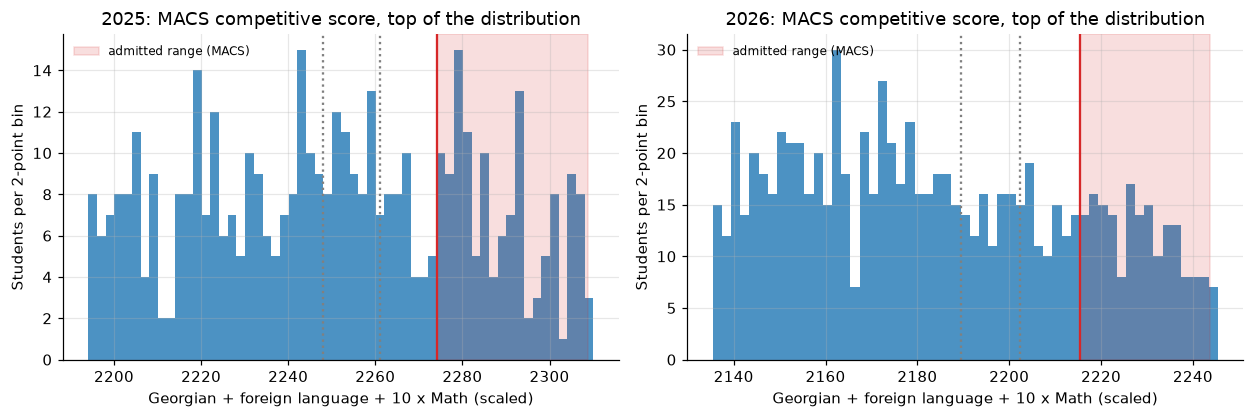

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
for ax, y in zip(axes, MACS):
    p = pops[y]
    cut = cut_t.set_index("year").loc[y, "cutoff"]
    top = cut_t.set_index("year").loc[y, "top_admitted"]
    d = p[p.comp >= cut - 80]
    ax.hist(d.comp, bins=np.arange(cut - 80, d.comp.max() + 2, 2), color="tab:blue", alpha=0.8)
    ax.axvspan(cut, top, color="tab:red", alpha=0.15, label="admitted range (MACS)")
    ax.axvline(cut, color="tab:red")
    for k in (1, 2):
        ax.axvline(cut - 13 * k, color="grey", ls=":")
    ax.set_title(f"{y}: MACS competitive score, top of the distribution")
    ax.set_xlabel("Georgian + foreign language + 10 x Math (scaled)")
    ax.set_ylabel("Students per 2-point bin")
    ax.legend(fontsize=8, frameon=False, loc="upper left")
fig.tight_layout()
savefig(fig, "fig04_macs_crowding")

## Figure 5 - What separates admitted MACS students (2026)
Admitted math-route students, sorted by competitive score; math raw score (colour) vs Georgian and English.

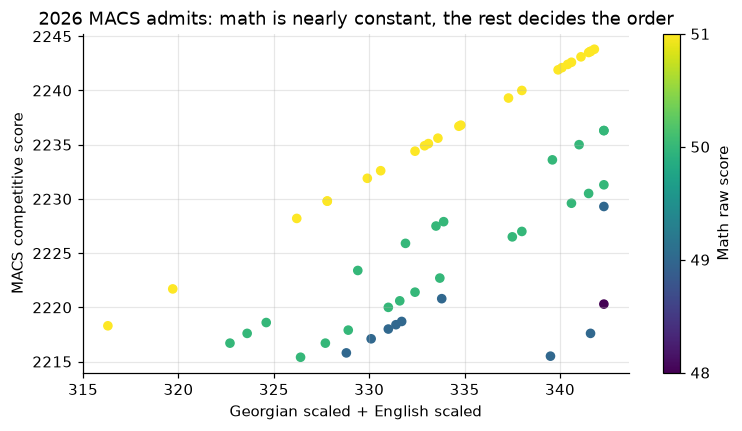

In [10]:
m = adms[2026][adms[2026].prog_code == MACS[2026]].sort_values("comp").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 4))
sc = ax.scatter(m.geo_sc + m.fl_sc, m.comp, c=m.el1_raw, cmap="viridis", s=28, vmin=48, vmax=51)
cb = fig.colorbar(sc, ax=ax, ticks=[48, 49, 50, 51])
cb.set_label("Math raw score")
ax.set_xlabel("Georgian scaled + English scaled")
ax.set_ylabel("MACS competitive score")
ax.set_title("2026 MACS admits: math is nearly constant, the rest decides the order")
savefig(fig, "fig05_macs_admits_2026")